# Regresi Linier: Metode Kuadrat Terkecil
**Metode Numerik · teori, algoritma, perhitungan, dan implementasi**

## 1. Dasar metode numerik
Regresi menentukan kecenderungan data pengukuran. Garis hampiran **tidak harus
melewati semua titik**, berbeda dengan interpolasi yang melalui titik data.
Model pengamatan adalah
$$y_i = a_0+a_1x_i+e_i,$$
dengan $x_i$ variabel bebas, $y_i$ pengamatan, $a_0$ intersep, $a_1$ kemiringan,
dan $e_i=y_i-\hat y_i$ residual.

Metode kuadrat terkecil meminimumkan
$$S_r(a_0,a_1)=\sum_{i=1}^{n}(y_i-a_0-a_1x_i)^2.$$
Residual dikuadratkan agar residual positif dan negatif tidak saling menghapus.
Notasi $S_r$ di sini mengikuti definisi jumlah **kuadrat** residual pada halaman 21.

## 2. Turunan dan persamaan normal
Syarat stasioner diperoleh dari dua turunan parsial:
$$\frac{\partial S_r}{\partial a_0}=-2\sum_{i=1}^{n}(y_i-a_0-a_1x_i)=0,$$
$$\frac{\partial S_r}{\partial a_1}=-2\sum_{i=1}^{n}x_i(y_i-a_0-a_1x_i)=0.$$
Susun ulang menjadi sistem persamaan linier:
$$\begin{aligned}
na_0+(\sum x_i)a_1&=\sum y_i,\\
(\sum x_i)a_0+(\sum x_i^2)a_1&=\sum x_iy_i.
\end{aligned}$$
Definisikan $S_x=\sum x_i$, $S_y=\sum y_i$, $S_{xx}=\sum x_i^2$,
$S_{xy}=\sum x_iy_i$. Koefisien dapat dihitung langsung:
$$D=nS_{xx}-S_x^2,$$
$$a_1=\frac{nS_{xy}-S_xS_y}{D},\qquad
 a_0=\bar y-a_1\bar x,\quad \bar x=S_x/n,\quad \bar y=S_y/n.$$
Secara matematis $D=n\sum(x_i-\bar x)^2$. Karena itu $D>0$ jika $x$ bervariasi.
Untuk $n\ge2$ dan $D>0$, matriks persamaan normal definit positif sehingga
solusinya merupakan minimum tunggal $S_r$.

Algoritma ini adalah penyelesaian langsung persamaan normal, bukan optimasi berulang.
Perulangannya hanya untuk menjumlahkan data dan mengevaluasi residual.

## 3. Urutan algoritma


In [8]:
from math import isfinite, isclose, sqrt

DATA = [(1, 0.5), (2, 2.5), (3, 2.0), (4, 4.0),
        (5, 3.5), (6, 6.0), (7, 5.5)]
x_prediksi = 4.0

print("Data contoh dari halaman 18")
print(" i      x       y      x^2      x*y")
for i, (x, y) in enumerate(DATA, start=1):
    print(f"{i:2d} {x:6.1f} {y:7.1f} {x*x:8.1f} {x*y:8.1f}")

Data contoh dari halaman 18
 i      x       y      x^2      x*y
 1    1.0     0.5      1.0      0.5
 2    2.0     2.5      4.0      5.0
 3    3.0     2.0      9.0      6.0
 4    4.0     4.0     16.0     16.0
 5    5.0     3.5     25.0     17.5
 6    6.0     6.0     36.0     36.0
 7    7.0     5.5     49.0     38.5


## 4. Implementasi mengikuti flowchart
Fungsi berikut menghitung koefisien secara manual. Tidak ada pemanggilan
fungsi regresi siap pakai. Masukan harus berupa pasangan bilangan hingga,
minimal dua pasangan, dan x harus bervariasi.

In [9]:
def regresi_linier(data):
    """Regresi kuadrat terkecil sesuai rumus pada halaman 17 dan 21."""
    n = len(data)
    if n < 2:
        raise ValueError("Minimal dua pasangan data diperlukan.")
    pasangan = []
    for baris in data:
        if not isinstance(baris, (tuple, list)) or len(baris) != 2:
            raise ValueError("Setiap baris harus berupa pasangan (x, y).")
        x, y = baris
        if (isinstance(x, bool) or isinstance(y, bool)
                or not isinstance(x, (int, float))
                or not isinstance(y, (int, float))):
            raise ValueError("x dan y harus berupa bilangan.")
        if not isfinite(x) or not isfinite(y):
            raise ValueError("x dan y harus hingga; NaN dan infinity tidak diterima.")
        pasangan.append((float(x), float(y)))

    sx = sy = sxx = sxy = 0.0
    for i in range(1, n + 1):
        x, y = pasangan[i - 1]
        sx += x
        sy += y
        sxx += x * x
        sxy += x * y
    d = n * sxx - sx * sx
    if not all(isfinite(v) for v in (sx, sy, sxx, sxy, d)):
        raise ValueError("Penjumlahan melampaui kapasitas numerik; skalakan data.")
    if d <= 0:
        raise ValueError("D tidak positif: x konstan atau terjadi kehilangan ketelitian.")

    # shortcut: rumus jumlah langsung mengikuti materi; gunakan data terpusat atau QR untuk x besar yang berdekatan.
    x_bar, y_bar = sx / n, sy / n
    a1 = (n * sxy - sx * sy) / d
    a0 = y_bar - a1 * x_bar
    if not isfinite(a0) or not isfinite(a1):
        raise ValueError("Koefisien tidak hingga; skalakan data.")

    sr = 0.0
    tabel = []
    for i in range(1, n + 1):
        x, y = pasangan[i - 1]
        y_hat = a0 + a1 * x
        e = y - y_hat
        e2 = e * e
        sr += e2
        tabel.append((i, x, y, y_hat, e, e2))
    if not isfinite(sr):
        raise ValueError("Kuadrat residual melampaui kapasitas numerik; skalakan data.")
    syx = sqrt(sr / (n - 2)) if n > 2 else None
    return {"n": n, "sx": sx, "sy": sy, "sxx": sxx, "sxy": sxy,
            "d": d, "x_bar": x_bar, "y_bar": y_bar,
            "a0": a0, "a1": a1, "sr": sr, "syx": syx, "tabel": tabel}

hasil = regresi_linier(DATA)
print("Fungsi siap. Data contoh berhasil dihitung.")

Fungsi siap. Data contoh berhasil dihitung.


## 5. Substitusi angka contoh
Pada halaman 19 diperoleh $n=7$, $S_x=28$, $S_y=24$, $S_{xx}=140$, $S_{xy}=119{,}5$.
Dengan demikian:
$$D=7(140)-28^2=196,$$
$$a_1=\frac{7(119{,}5)-28(24)}{196}=0{,}83928571,$$
$$a_0=\frac{24}{7}-0{,}83928571\frac{28}{7}=0{,}07142857.$$

In [10]:
print(f"n       = {hasil['n']}")
for nama in ["sx", "sy", "sxx", "sxy", "d", "x_bar", "y_bar"]:
    print(f"{nama:7s} = {hasil[nama]:.8f}")
print(f"\na0      = {hasil['a0']:.8f}")
print(f"a1      = {hasil['a1']:.8f}")
print(f"Garis   : y_hat = {hasil['a0']:.8f} {hasil['a1']:+.8f} x")

n       = 7
sx      = 28.00000000
sy      = 24.00000000
sxx     = 140.00000000
sxy     = 119.50000000
d       = 196.00000000
x_bar   = 4.00000000
y_bar   = 3.42857143

a0      = 0.07142857
a1      = 0.83928571
Garis   : y_hat = 0.07142857 +0.83928571 x


## 6. Residual dan galat baku estimasi
Sesuai halaman 21, hitung prediksi $\hat y_i=a_0+a_1x_i$ dan residual
$e_i=y_i-\hat y_i$. Lalu:
$$S_r=\sum e_i^2,\qquad s_{y/x}=\sqrt{\frac{S_r}{n-2}}.$$
Penyebut $n-2$ adalah derajat bebas residual, karena dua parameter ($a_0$ dan $a_1$)
diestimasi. Untuk $n=2$, garis masih dapat dihitung jika x berbeda, tetapi galat
baku ini **tidak terdefinisi**. $S_r$ mempunyai satuan y kuadrat, sedangkan
$s_{y/x}$ mempunyai satuan yang sama dengan y.

In [11]:
print(" i      x       y      y_hat     residual    residual^2")
for i, x, y, y_hat, e, e2 in hasil["tabel"]:
    print(f"{i:2d} {x:6.1f} {y:7.1f} {y_hat:10.6f} {e:12.6f} {e2:13.6f}")
print(f"\nSr = {hasil['sr']:.8f}")
if hasil["syx"] is None:
    print("s_y/x tidak terdefinisi untuk n = 2.")
else:
    print(f"s_y/x = sqrt({hasil['sr']:.8f} / {hasil['n'] - 2})")
    print(f"s_y/x = {hasil['syx']:.8f}")

 i      x       y      y_hat     residual    residual^2
 1    1.0     0.5   0.910714    -0.410714      0.168686
 2    2.0     2.5   1.750000     0.750000      0.562500
 3    3.0     2.0   2.589286    -0.589286      0.347258
 4    4.0     4.0   3.428571     0.571429      0.326531
 5    5.0     3.5   4.267857    -0.767857      0.589605
 6    6.0     6.0   5.107143     0.892857      0.797194
 7    7.0     5.5   5.946429    -0.446429      0.199298

Sr = 2.99107143
s_y/x = sqrt(2.99107143 / 5)
s_y/x = 0.77344314


## 7. Prediksi dan interpretasi
Untuk contoh $x=4$, prediksi berada di dalam rentang data $[1,7]$.
Nilai yang diperoleh adalah nilai dari garis regresi, sehingga tidak harus sama
dengan pengamatan $y=4$. Galat baku estimasi bukan batas maksimum galat maupun
jaminan ketepatan satu prediksi. Prediksi di luar rentang data adalah ekstrapolasi
dan perlu kehati-hatian.

In [12]:
if not isfinite(x_prediksi):
    raise ValueError("x_prediksi harus berupa bilangan hingga.")
y_prediksi = hasil["a0"] + hasil["a1"] * x_prediksi
print(f"Untuk x = {x_prediksi:g}, prediksi y = {y_prediksi:.8f}")
print(f"Artinya: kenaikan satu satuan x mengubah prediksi y sebesar {hasil['a1']:.8f}.")

Untuk x = 4, prediksi y = 3.42857143
Artinya: kenaikan satu satuan x mengubah prediksi y sebesar 0.83928571.


## 8. Grafik garis hampiran dan residual
Garis vertikal pada panel kiri memperlihatkan selisih pengamatan terhadap prediksi.
Panel kanan memperlihatkan residual terhadap x. Grafik membantu pemeriksaan pola;
tujuh titik ini saja belum cukup untuk membuktikan seluruh asumsi statistik model.

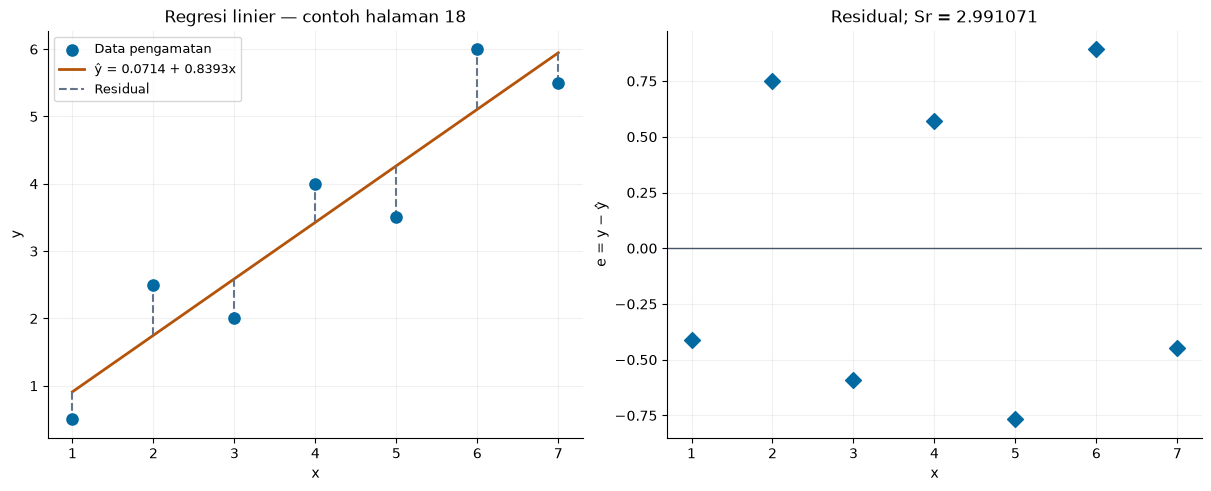

In [13]:
import matplotlib.pyplot as plt

x_data = [baris[1] for baris in hasil["tabel"]]
y_data = [baris[2] for baris in hasil["tabel"]]
y_hat = [baris[3] for baris in hasil["tabel"]]
residual = [baris[4] for baris in hasil["tabel"]]
x_garis = [min(x_data), max(x_data)]
y_garis = [hasil["a0"] + hasil["a1"] * x for x in x_garis]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)
axes[0].scatter(x_data, y_data, s=65, color="#0369a1", label="Data pengamatan", zorder=3)
axes[0].plot(x_garis, y_garis, color="#b45309", linewidth=2,
             label=f"ŷ = {hasil['a0']:.4f} + {hasil['a1']:.4f}x")
axes[0].vlines(x_data, y_hat, y_data, color="#64748b", linestyle="--", label="Residual")
axes[0].set(title="Regresi linier — contoh halaman 18", xlabel="x", ylabel="y")
axes[0].legend(fontsize=9)
axes[1].axhline(0, color="#475569", linewidth=1)
axes[1].scatter(x_data, residual, s=65, marker="D", color="#0369a1", zorder=3)
axes[1].set(title=f"Residual; Sr = {hasil['sr']:.6f}", xlabel="x", ylabel="e = y − ŷ")
for ax in axes:
    ax.grid(True, alpha=0.18)
    ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 9. Pemeriksaan hasil dan kondisi khusus
Uji berikut membandingkan koefisien dengan nilai eksak contoh,
memeriksa kondisi persamaan normal melalui residual, dan menguji data khusus.
Pembandingan dengan nilai eksak memakai toleransi karena Python menghitung
menggunakan bilangan titik mengambang.

In [14]:
contoh = regresi_linier([(1, 0.5), (2, 2.5), (3, 2.0), (4, 4.0),
                        (5, 3.5), (6, 6.0), (7, 5.5)])
assert isclose(contoh["a0"], 1 / 14, abs_tol=1e-12)
assert isclose(contoh["a1"], 47 / 56, abs_tol=1e-12)
assert isclose(contoh["sr"], 335 / 112, abs_tol=1e-12)
assert isclose(contoh["syx"], sqrt(67 / 112), abs_tol=1e-12)
assert abs(sum(b[4] for b in contoh["tabel"])) < 1e-12
assert abs(sum(b[1] * b[4] for b in contoh["tabel"])) < 1e-12
sempurna = regresi_linier([(1, 3), (2, 5), (3, 7)])
assert (sempurna["a0"], sempurna["a1"], sempurna["sr"]) == (1.0, 2.0, 0.0)
dua_titik = regresi_linier([(0, 1), (1, 3)])
assert dua_titik["syx"] is None
for data_salah in ([], [(1, 2)], [(2, 1), (2, 3)],
                    [(1, float("nan")), (2, 3)], [(1, 2, 3), (2, 3)],
                    [("1", 2), (2, 3)]):
    try:
        regresi_linier(data_salah)
    except ValueError:
        pass
    else:
        raise AssertionError(f"Data seharusnya ditolak: {data_salah}")
print("LULUS: contoh materi, kondisi persamaan normal, garis sempurna,")
print("       dua titik, dan seluruh contoh data tidak valid.")

LULUS: contoh materi, kondisi persamaan normal, garis sempurna,
       dua titik, dan seluruh contoh data tidak valid.


## 10. Kesimpulan dan batas numerik
Untuk data asli materi:
- Garis regresi: $\hat y=0{,}07142857+0{,}83928571x$.
- Jumlah kuadrat residual: $S_r=2{,}99107143$.
- Galat baku estimasi: $s_{y/x}=0{,}77344314$.
- Prediksi contoh pada $x=4$: $\hat y=3{,}42857143$.

Koefisien cocok dengan halaman 20. Galat baku menjawab pertanyaan pada halaman 21.
Metode kuadrat terkecil memberikan garis terbaik **untuk model linier dan fungsi
objektif yang dipilih**, bukan bukti hubungan sebab-akibat.

**Batas numerik:** pengurangan $nS_{xx}-S_x^2$ dapat kehilangan angka signifikan
untuk nilai x sangat besar yang saling berdekatan. Untuk kasus tersebut, pusatkan
atau skalakan x, atau gunakan penyelesaian berbasis QR. Fungsi di sini mempertahankan
rumus langsung agar langkahnya sama dengan materi dan flowchart.

**Pemetaan referensi:** halaman 12–15: pencocokan kurva dan regresi; halaman 16–17:
model, residual, persamaan normal; halaman 18–20: data dan koefisien contoh;
halaman 21: jumlah kuadrat residual dan galat baku estimasi.